# Étape 10.2 : la même allocation, en long-short

Tout est repris de l'étape 9 : mêmes actions du S&P 500, mêmes z-scores, mêmes scores finaux (équipondéré et ERC), même zone tampon, même plafond, mêmes frais. Une seule chose change : on **vend à découvert** les actions au plus mauvais score, en plus d'acheter les meilleures.

## 1. Données, scores et outils de l'étape 9

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

# Contrôle : contributions au risque au dernier mois
cov_fin = facteurs.loc[:mois[-1], list(STYLES.values())].iloc[-60:].cov().values
print("Contributions au risque (dernier mois) :", np.round(contributions(poids.iloc[-1].values, cov_fin), 3))
print("\nPoids ERC des facteurs dans le score, résumé sur la période :")
poids.describe().loc[["mean", "min", "max"]].round(2)

Contributions au risque (dernier mois) : [0.2 0.2 0.2 0.2 0.2]

Poids ERC des facteurs dans le score, résumé sur la période :


,SMB,HML,RMW,CMA,Mom
mean,0.23,0.13,0.30,0.18,0.17
min,0.17,0.08,0.25,0.12,0.08
max,0.32,0.22,0.36,0.23,0.22


In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})
print(f"{len(scores):,}".replace(",", " "), "scores (mois, action)")
print(f"Corrélation entre les deux scores : {scores.corr().iloc[0, 1]:.2f}")
scores.to_csv(ROOT / "data" / "processed" / "scores_finaux_sp500.csv.gz", float_format="%.5g")

72 741 scores (mois, action)
Corrélation entre les deux scores : 0.92


In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}

In [8]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])

## 2. Le portefeuille long-short

Chaque fin de mois $t$ :

- **Jambe achetée** : exactement le portefeuille de l'étape 9. Les 30 % meilleurs scores (gardés tant qu'ils restent dans les 40 % meilleurs), poids $\propto \text{capitalisation} \times (1 + S)$, plafond de 10 %.
- **Jambe vendue** : le miroir. Les 30 % plus mauvais scores (gardés tant qu'ils restent dans les 40 % plus mauvais), poids $\propto \text{capitalisation} \times (1 - S)$ : plus le score est mauvais, plus on vend. Plafond de 10 %.
- **Autant vendu qu'acheté** : 1 $ acheté pour 1 $ vendu. L'argent de la vente à découvert et le capital de départ restent placés au taux sans risque.

Rendement mensuel du fonds :

$$r_{t+1} = r_f + \underbrace{r^{\text{achetées}}_{t+1} - r^{\text{vendues}}_{t+1}}_{\text{pari sur les facteurs}} - \text{frais}$$

C'est la construction des facteurs de Fama et French (jambes pondérées par la capitalisation, 30 % / 30 %), avec en plus l'inclinaison par le score.

**Frais** :
- 0,10 % par dollar échangé, sur les deux jambes, comme à l'étape 9 ;
- **coût d'emprunt** des titres vendus : 0,25 % par an. C'est le tarif courant pour des grandes capitalisations américaines faciles à emprunter (D'Avolio, 2002). Sensibilité plus bas.

In [9]:
EMPRUNT = 0.0025


def poids_long_short(score, seuil=0.30, tampon=0.40):
    jambes, tenus = {}, {"achat": set(), "vente": set()}
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        sortie = {}
        for jambe, rang in [("achat", s.rank(ascending=False, pct=True)), ("vente", s.rank(ascending=True, pct=True))]:
            selection = set(rang[rang <= seuil].index) | (set(rang[rang <= tampon].index) & tenus[jambe])
            selection = sorted(selection)
            tenus[jambe] = set(selection)
            inclinaison = (1 + s[selection]) if jambe == "achat" else (1 - s[selection])
            sortie[jambe] = plafonner(c[selection] * inclinaison.clip(lower=0))
        jambes[m] = sortie
    return jambes


def backtest_long_short(jambes, frais=0.0010, emprunt=EMPRUNT):
    lignes = {}
    derive = {"achat": pd.Series(dtype=float), "vente": pd.Series(dtype=float)}
    for m, j in jambes.items():
        r_jambe, rotation = {}, 0.0
        for nom, w in j.items():
            rotation += w.subtract(derive[nom], fill_value=0).abs().sum()
            r = rendements.loc[m + 1].reindex(w.index).fillna(0)
            r_jambe[nom] = float((w * r).sum())
            nouveau = w * (1 + r)
            derive[nom] = nouveau / nouveau.sum()
        pari = r_jambe["achat"] - r_jambe["vente"]
        excedent = pari - frais * rotation - emprunt / 12
        lignes[m + 1] = {"achetées": r_jambe["achat"], "vendues": r_jambe["vente"], "pari brut": pari,
                         "rotation": rotation, "excédent net": excedent,
                         "net": rf.get(m + 1, 0.0) + excedent}
    return pd.DataFrame(lignes).T


jambes = {"équipondéré": poids_long_short(scores["score_equipondere"]),
          "ERC": poids_long_short(scores["score_erc"])}
long_short = {f"Long-short {k}": backtest_long_short(v) for k, v in jambes.items()}
long_only = {"Long-only équipondéré (étape 9)": backtest(poids_cibles(scores["score_equipondere"])),
             "Long-only ERC (étape 9)": backtest(poids_cibles(scores["score_erc"]))}
univers = backtest({m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]})
periode = univers.index

for k, v in jambes.items():
    n_a = np.mean([len(x["achat"]) for x in v.values()])
    n_v = np.mean([len(x["vente"]) for x in v.values()])
    print(f"{k} : {n_a:.0f} actions achetées et {n_v:.0f} vendues en moyenne")
print(f"Période : {periode[0]} à {periode[-1]}, {len(periode)} mois")

équipondéré : 141 actions achetées et 139 vendues en moyenne
ERC : 142 actions achetées et 140 vendues en moyenne
Période : 2012-03 à 2026-08, 174 mois


## 3. Résultats

In [10]:
def indicateurs(r):
    r = r.reindex(periode)
    exces = r - rf.reindex(periode)
    valeur = (1 + r).cumprod()
    return pd.Series({
        "rendement annuel": valeur.iloc[-1] ** (12 / len(r)) - 1,
        "volatilité": r.std() * np.sqrt(12),
        "Sharpe": exces.mean() / exces.std() * np.sqrt(12),
        "perte maximale": (valeur / valeur.cummax() - 1).min(),
    })


series = {k: v["net"] for k, v in long_only.items()}
series.update({k: v["net"] for k, v in long_short.items()})
series["Univers (capitalisation)"] = univers["net"]
series["SPY"] = rend_etf["SPY"]
resultats = pd.DataFrame({k: indicateurs(v) for k, v in series.items()}).T
toutes = {**long_only, **long_short}
resultats["rotation annuelle"] = [toutes[k]["rotation"].iloc[1:].mean() * 12 if k in toutes else np.nan
                                  for k in resultats.index]
resultats.style.format({"rendement annuel": "{:.1%}", "volatilité": "{:.1%}", "Sharpe": "{:.2f}",
                        "perte maximale": "{:.1%}", "rotation annuelle": "{:.0%}"}, na_rep="")

,rendement annuel,volatilité,Sharpe,perte maximale,rotation annuelle
Long-only équipondéré (étape 9),15.6%,15.8%,0.90,-28.2%,315%
Long-only ERC (étape 9),14.7%,15.4%,0.87,-23.2%,278%
Long-short équipondéré,0.7%,10.6%,-0.03,-32.4%,460%
Long-short ERC,-0.0%,9.4%,-0.13,-38.5%,404%
Univers (capitalisation),15.1%,14.0%,0.96,-23.6%,
SPY,14.6%,14.0%,0.93,-23.9%,


### Le pari long-short rapporte-t-il quelque chose ?

On teste si l'excédent net du long-short (au-dessus du taux sans risque) est différent de zéro, et on compare son Sharpe à celui du long-only de l'étape 9. Mêmes outils qu'à l'étape 9 : $t$ de Newey-West et bootstrap par blocs.

In [11]:
lignes = []
for (nom_ls, nom_lo) in [("Long-short équipondéré", "Long-only équipondéré (étape 9)"),
                         ("Long-short ERC", "Long-only ERC (étape 9)")]:
    e = long_short[nom_ls]["excédent net"]
    moy, t, p = test_moyenne(e)
    ic_actif, ic_sharpe = bootstrap(long_short[nom_ls]["net"], long_only[nom_lo]["net"])
    rng = np.random.default_rng(1)
    moyennes = [e.values[indices_bootstrap(len(e), 6, rng)].mean() * 12 for _ in range(5000)]
    lignes.append({"stratégie": nom_ls, "excédent annuel": 12 * moy, "t (Newey-West)": t, "p-valeur": p,
                   "IC 95 % excédent": f"[{np.percentile(moyennes, 2.5):+.1%} ; {np.percentile(moyennes, 97.5):+.1%}]",
                   "écart de Sharpe avec le long-only": sharpe(long_short[nom_ls]["net"], rf.reindex(periode))
                   - sharpe(long_only[nom_lo]["net"], rf.reindex(periode)),
                   "IC 95 % écart de Sharpe": f"[{ic_sharpe[0]:+.2f} ; {ic_sharpe[1]:+.2f}]"})
pd.DataFrame(lignes).set_index("stratégie").style.format(
    {"excédent annuel": "{:+.2%}", "t (Newey-West)": "{:+.2f}", "p-valeur": "{:.2f}",
     "écart de Sharpe avec le long-only": "{:+.2f}"})

,excédent annuel,t (Newey-West),p-valeur,IC 95 % excédent,écart de Sharpe avec le long-only,IC 95 % écart de Sharpe
stratégie,,,,,,
Long-short équipondéré,-0.37%,-0.12,0.90,[-5.9% ; +5.3%],-0.94,[-1.47 ; -0.45]
Long-short ERC,-1.23%,-0.46,0.64,[-6.2% ; +3.6%],-1.00,[-1.53 ; -0.48]


In [12]:
# Les deux jambes séparément (rendement annuel moyen, brut)
pd.DataFrame({k: {"actions achetées": 12 * v["achetées"].mean(), "actions vendues": 12 * v["vendues"].mean(),
                  "écart": 12 * v["pari brut"].mean()} for k, v in long_short.items()}).T.style.format("{:+.2%}")

,actions achetées,actions vendues,écart
Long-short équipondéré,+16.18%,+15.83%,+0.35%
Long-short ERC,+15.25%,+15.81%,-0.56%


### Expositions aux six facteurs

Régression de l'excédent net sur les facteurs de Fama et French, comme à l'étape 9.

In [13]:
SIX = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
X = sm.add_constant(facteurs.loc[periode, SIX])
expo = {}
for nom, r in [("Long-only équipondéré (étape 9)", long_only["Long-only équipondéré (étape 9)"]["net"]),
               ("Long-only ERC (étape 9)", long_only["Long-only ERC (étape 9)"]["net"]),
               ("Long-short équipondéré", long_short["Long-short équipondéré"]["net"]),
               ("Long-short ERC", long_short["Long-short ERC"]["net"])]:
    m = sm.OLS(r - rf.reindex(periode), X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    ligne = m.params.rename({"const": "alpha annuel"})
    ligne["alpha annuel"] *= 12
    ligne["t alpha"] = m.tvalues["const"]
    ligne["R²"] = m.rsquared
    expo[nom] = ligne
expositions = pd.DataFrame(expo).T
expositions.style.format("{:.2f}").format("{:+.1%}", subset=["alpha annuel"])

,alpha annuel,Mkt-RF,SMB,HML,RMW,CMA,Mom,t alpha,R²
Long-only équipondéré (étape 9),+0.4%,1.03,0.09,0.39,-0.00,0.15,0.16,0.35,0.93
Long-only ERC (étape 9),-0.7%,1.04,0.11,0.21,0.03,0.19,0.20,-0.53,0.91
Long-short équipondéré,-1.0%,0.03,0.33,0.55,-0.05,0.26,0.24,-0.55,0.67
Long-short ERC,-2.1%,0.04,0.33,0.32,-0.01,0.30,0.26,-1.04,0.51


### Robustesse : sous-périodes et frais

In [14]:
lignes = {}
for nom, bt in long_short.items():
    for sp, (d, f) in {"2012-2019": ("2012-03", "2019-12"), "2020-2026": ("2020-01", "2026-08")}.items():
        e = bt["excédent net"].loc[d:f]
        moy, t, _ = test_moyenne(e)
        lignes[(nom, sp)] = {"excédent annuel": 12 * moy, "Sharpe": e.mean() / e.std() * np.sqrt(12), "t (Newey-West)": t}
pd.DataFrame(lignes).T.style.format({"excédent annuel": "{:+.2%}", "Sharpe": "{:+.2f}", "t (Newey-West)": "{:+.2f}"})

In [15]:
# Excédent annuel selon les frais de transaction et le coût d'emprunt
lignes = {}
for frais_pb in [0, 10, 25]:
    for emprunt in [0.0, 0.0025, 0.01]:
        lignes[(f"{frais_pb} pb", f"{emprunt:.2%}")] = {
            nom: 12 * (bt["pari brut"] - frais_pb / 1e4 * bt["rotation"] - emprunt / 12).mean()
            for nom, bt in long_short.items()}
pd.DataFrame(lignes).T.rename_axis(["frais par dollar échangé", "coût d'emprunt annuel"]).style.format("{:+.2%}")

## 4. Graphique

In [16]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

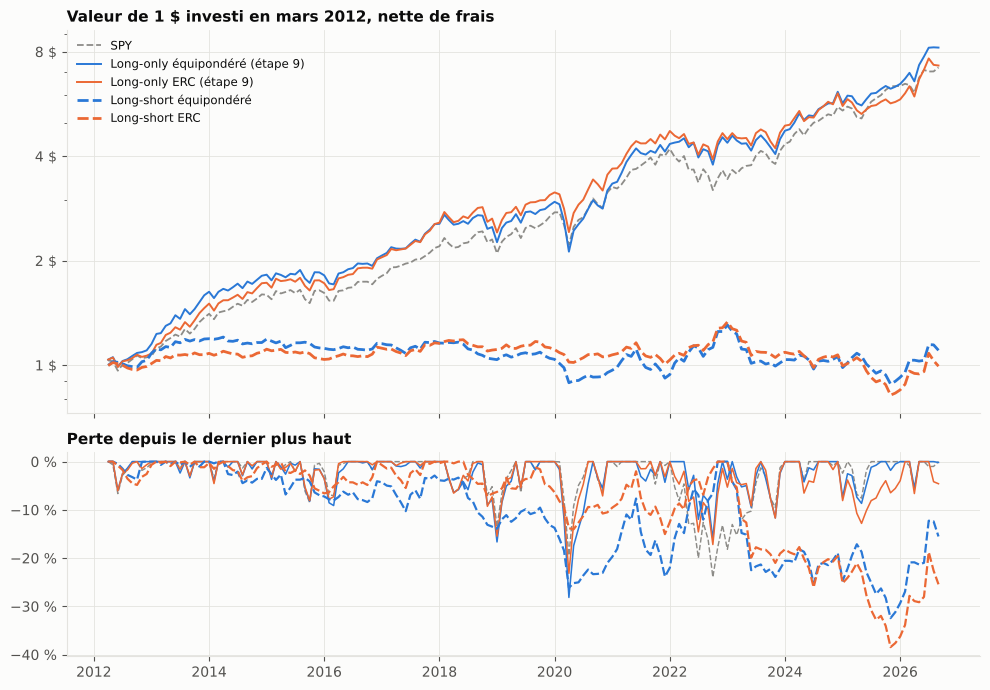

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
d = periode.to_timestamp(how="end")
traces = [("SPY", GRIS, "--", 1.3), ("Long-only équipondéré (étape 9)", BLEU, "-", 1.4),
          ("Long-only ERC (étape 9)", ORANGE, "-", 1.4),
          ("Long-short équipondéré", BLEU, (0, (4, 1.5)), 2.0), ("Long-short ERC", ORANGE, (0, (4, 1.5)), 2.0)]
for nom, couleur, style, lw in traces:
    r = series[nom].reindex(periode)
    v = (1 + r).cumprod()
    ax1.plot(d, v, color=couleur, ls=style, lw=lw, label=nom)
    ax2.plot(d, 100 * (v / v.cummax() - 1), color=couleur, ls=style, lw=lw * 0.8)
ax1.set_yscale("log")
ax1.set_yticks([1, 2, 4, 8])
ax1.yaxis.set_major_formatter(virgule("{:.0f} $"))
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_title("Valeur de 1 $ investi en mars 2012, nette de frais")
ax1.legend(loc="upper left", fontsize=8.5)
ax2.yaxis.set_major_formatter(virgule("{:.0f} %"))
ax2.set_title("Perte depuis le dernier plus haut")
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
sauver(fig, "long_short_backtest.png")
plt.show()